# Best Neighborhood in Pittsburgh for a Family

## Team District 23
**Nathan -> Housing Price, Cooper -> Crime, Eddie -> Schools, Owen -> Bus Access**

### Introduction 
For our final project, the "best neighborhhod" is the one where a family can enjoy living and build a life in Pittsburgh. To find it, we considered four things that matter most to a family:
- **Housing price:** The family needs a home that can fits their budget of $400,000.

- **Crime:** A lower crime rate gives the family safety and peace of mind.

- **School:** The children need good schools nearby. 

- **Bus access:** The family needs public transit to commute to work, and their children need to get around the city easily.

### The Metric:
Each of us made a score from 0 to 1 for every neighborhood, where a higher score is better. We combined the four scores by taking their average, so each sub-metric counts equally. The neighborhood with the highest average score is our best neighborhood.

### Housing price 
For housing price, I used property sales from 2024 to 2026 from the WPRDC website. Our team decided the family has a budget of $400,000, so I used it as a guideline to find which neighborhoods are out of their price range, and found the median sale price in each Pittsburgh neighborhood. 

Finding the correct data was a challenge. First, I had to keep only the valid house sales. Some sales, like family transfers or foreclosures, are counted as house sales, but the price doesn't show the real housing price in that area. Some families even give their property to their children for $1! Second, a lot of homes outside the city still have "Pittsburgh" in their address, so I had to figure out which sales are really inside the city limits. Pittsburgh uses the word "Ward" for this, so if a sale is in a Pittsburgh ward, it's inside the city. This way I removed a lot of sales that looked like they were in a city neighborhood but were actually outside the city. Third, I first tried using ZIP codes with the fpsnippets tool. But many neighborhoods share the same ZIP code, so one house sale got counted in several neighborhoods, and a lot of neighborhoods ended up with the same median price. That wasn't really accurate. So I used another dataset, Parcel Centroids found on WPRDC webbsite, and matched each sale's parcel ID to find exactly which neighborhood it's in. Even with 3 years of sales, some neighborhoods still have very few sales, so their median price might not show the real market price. Once every sale had the right neighborhood, I gave each one a score. Anything within the budget gets 1.0. Anything over the budget gets a lower score: the budget divided by its median price. 

65 of 80 neighborhoods fit the budget, so they all have a score of 1.0. 

Squirrel Hill North has the lowest score (median $775,000, score 0.52). A lower housing score doesn't mean a neighborhood is bad. 

I really love the Squirrel Hill North neighborhood. It has some awesome houses, the gardens are so pretty, and it's close to Pitt and other shopping streets. But the housing prices are just so high that they push the average family out of this area. That doesn't mean it's out of the running, because sometimes people do buy a house over their budget, as long as the neighborhood fits their other needs.

### Schools
.....

### Bus access 
...

### Crime rate
...

### The Best Neighborhood : 
bc ....

## The DATA
Each of us made a score file in our individual notebook. In this final notebook, we load these four files and combine them:
- `hosing_socres.csv` -> Nathan
- `crime_socres.csv` -> Cooper
- `Eddie' file` -> Eddie 
- `Owen file ` -> Owen 


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
#load all score data sets ["Neighborhood", "Metric Name"]
crime_scores = pd.read_csv("data/crime_scores.csv")
housing_scores = pd.read_csv("data/housing_scores.csv")
#transit_scores = pd.read_csv("")
#school_scores = pd.read_csv("")

Some neighborhoods are not in our final ranking because they were missing from at least one of our individual notebooks. For example, in the housing price-metric, 10 neighborhoods had no valid sales from 2024 - 2025, so they have no housing scores.

### Crime
.....

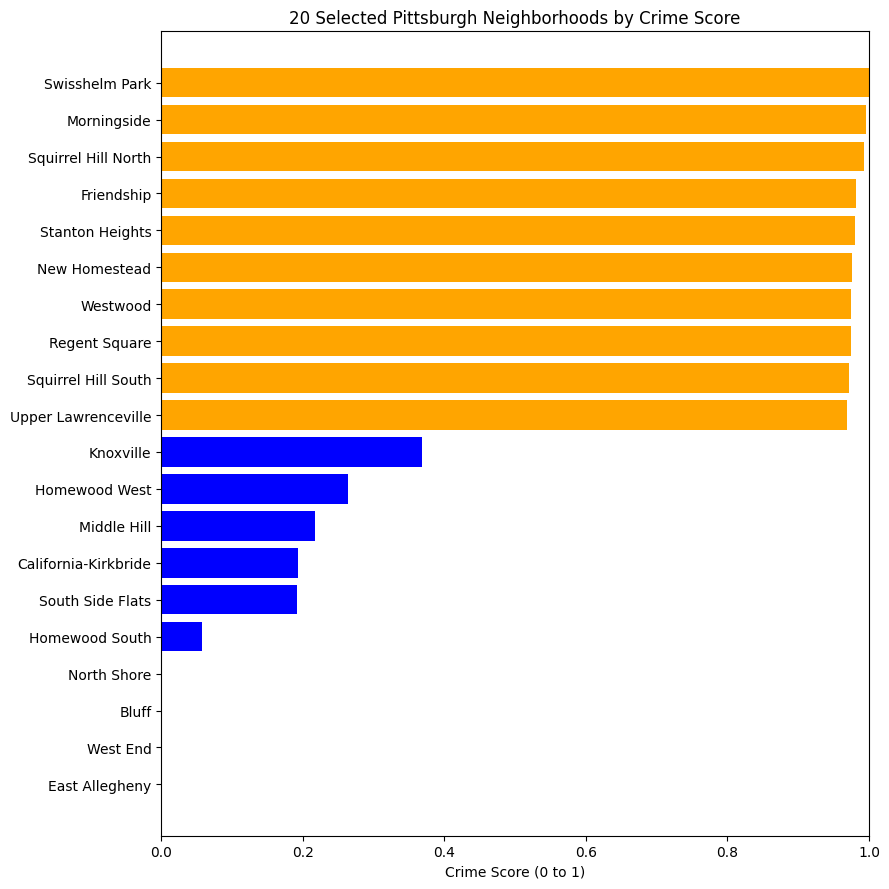

In [3]:
#analyzing the crime score data (Author: Cooper)
sorted = crime_scores.sort_values(by = "Crime Score")
bottom10 = sorted.head(10)
top10 = sorted.tail(10)
together = pd.concat([bottom10, top10])

colors = ["orange" if neighborhood in top10.index else "blue" for neighborhood in together.index]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(together["Neighborhood"], together["Crime Score"], color=colors)
ax.set_title("20 Selected Pittsburgh Neighborhoods by Crime Score")
ax.set_xlabel("Crime Score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [4]:
print("Great Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.8, 1.0)].shape[0]))
print("Good Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.6, 0.8)].shape[0]))
print("Decent Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.4, 0.6)].shape[0]))
print("Fine Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.2, 0.4)].shape[0]))
print("Bad Neighborhoods: " + str(crime_scores[crime_scores["Crime Score"].between(0.0, 0.2)].shape[0]))

Great Neighborhoods: 46
Good Neighborhoods: 17
Decent Neighborhoods: 9
Fine Neighborhoods: 4
Bad Neighborhoods: 7


Pittsburgh has many neighborhoods with low crime rates, but a few neighborhoods with very high crime rates. An effective final metric should rank the bottom seven to eleven neighborhoods lower than the other 72.

## Housing Price 
......
code .. 


### Schools
.....

### Bus access 
...

# Merge

In [ ]:
#merge all score sets and trim into final df
merged_df = crime_scores.merge(housing_scores, on = "Neighborhood", how = "inner").merge(transit_scores, on = "Neighborhood", how = "inner").merge(school_scores, on = "Neighborhood", how = "inner")
print(merged_df.shape)
merged_df["Combined Score"] = (merged_df["Crime Score"] + merged_df["Housing Score"] + merged_df[""] + merged_df[""]) / 4
final_scores = merged_df[["Neighborhood", "Combined Score"]]
final_scores

NameError: name 'transit_scores' is not defined

In [ ]:
#Plot 10 best neighborhoods and 10 worst neighborhoods (Authors: Cooper, )

sorted = final_scores.sort_values(by = "Combined Score")
bottom10 = sorted.head(10)
top10 = sorted.tail(10)
together = pd.concat([bottom10, top10])

colors = ["orange" if neighborhood in top10.index else "blue" for neighborhood in together.index]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(together["Neighborhood"], together["Combined Score"], color=colors)
ax.set_title("20 Selected Pittsburgh Neighborhoods by Combined Score")
ax.set_xlabel("Combined Score (0 to 1)")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()


This is where we will analyze the final scores!